# Short experiment: how long does a small kick stay predictable?

LPJ-GUESS (cohort mode, one grid cell, constant climate, no random numbers) is a deterministic system. We nudge its state with ten small kicks at once (every kick between -1 % and +1 %, temperature +-0.1 K) and follow the difference to an unperturbed control run for 512 years. For every horizon we ask:

1. How large is the response of the whole state? (response size)
2. Can a linear model predict the response from the kicks? (R2 on held-out runs)
3. Which kicks matter? (arrow length of the LASSO coefficients)

Data: `data/p1400_twin_runs.csv`, experiment `short_kick`: 100 perturbed runs and 1 control for each of the two modes (`A_nofire`, `C_fire_accumulate`).

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import MultiTaskLasso, MultiTaskLassoCV
from sklearn.model_selection import KFold
import plotlib as pl

pl.slide_style()
FIG = "figures/"                  # figures are written here
os.makedirs(FIG, exist_ok=True)

## Settings

In [2]:
HORIZONS = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512]   # years after the kick (two per octave)
VARIABLES = ["cmass_Total", "lai_Total", "dens_TrBE", "anpp_Total",
             "cflux_NEE", "cflux_Soil", "cflux_Veg", "npool_Total"]   # the state: biomass, LAI, tree density, NPP, C fluxes, N pool
TEST_SHARE = 0.3       # share of the runs that is never used for fitting
N_BOOT = 100           # bootstrap draws
MIN_SHARE = 0.95       # heatmap: show a kick only where it was selected in >= 95 % of the draws
SEED = 0

## 1. Load the data and build the state difference

The state of a run at a horizon is the vector of the eight variables. We subtract the control and divide every variable by one scale (its RMS over all runs, horizons and both modes), so all variables count equally and both modes share the same units (z-units).

In [3]:
df = pd.read_csv("data/p1400_twin_runs.csv")
df = df[df.experiment == "short_kick"]
kicks = [c for c in df.columns if c.startswith("u_")]         # the ten kick columns, u in [-1, 1]
modes = list(pl.MODE_COLORS)

differences, X = {}, {}
for mode in modes:
    sub = df[df["mode"] == mode]
    diffs = []
    for v in VARIABLES:
        wide = sub.pivot(index="member", columns="t", values=v)[HORIZONS]     # first row = control
        diffs.append(wide.iloc[1:].values - wide.iloc[0].values)
    differences[mode] = np.stack(diffs, axis=2)                               # [run, horizon, variable]
    X[mode] = sub[sub.t == 0].set_index("member").loc[wide.index[1:], kicks].values   # kicks of every run are stored in X

stacked = np.concatenate([d.reshape(-1, len(VARIABLES)) for d in differences.values()])
scale = np.sqrt(np.mean(stacked ** 2, axis=0))

print("kicks:", kicks)
r = np.corrcoef(X[modes[0]].T)
print(f"largest |correlation| between two kicks: {np.abs(r[np.triu_indices(len(kicks), 1)]).max():.2f}")
# correlation between kick series eg. 100 for rain vs 100 for sw radiation, if too similar, the linear model
# cannot say who produced the effect.

kicks: ['u_sap_c', 'u_heart_c', 'u_tree_density', 'u_litter_c', 'u_soil_c_fast', 'u_soil_c_slow', 'u_soil_n', 'u_rain', 'u_temp', 'u_sun']
largest |correlation| between two kicks: 0.27


### Why these methods

- Linear regression: for small kicks a smooth system responds roughly linearly. So "can a linear model predict the response on runs it has not seen?" is a direct test of predictability. Where the test R2 falls, the linear regime ends.
- LASSO instead of least squares: we want to know which kicks matter. The penalty sets unimportant kicks exactly to zero. The multi-task version keeps or drops a kick for all eight variables together. 
- Cross-validation (5-fold, inside the training runs) chooses the penalty alpha without using the test runs. The 30 % test runs give an honest R2.
- Bootstrap shows how much R2, response size and arrow lengths change with other runs, and how often a kick is selected. The heatmap only shows kicks selected in at least 95 % of the draws.
- The kicks need no scaling, they lie in [-1, 1] by design. The outputs are put on one scale (z-units) so no variable dominates.

### Limitations

- Linear model: when R2 falls, we cannot tell if the response is non-linear or unpredictable.
- LASSO shrinks the coefficients. With correlated kicks it picks one of them somewhat arbitrarily, but here they are only weakly correlated (largest |r| above).
- Alpha is chosen from 70 runs per horizon and is noisy. The bootstrap keeps alpha fixed, so the bands ignore that.
- One random train/test split. The z-scale also uses the test runs.

## 2. Fit: multi-task LASSO per horizon

For every horizon all eight variables are predicted from the ten kicks at once. The group penalty (alpha times the sum of the lengths of the coefficient vectors of all kicks) keeps or removes a kick for the whole state. Alpha comes from cross-validation inside the 70 % training runs, R2 from the 30 % test runs. The bootstrap resamples training and test runs (refit with fixed alpha) and gives the min-max bands.

In [4]:
def fit_state_response(X, z):
    rng = np.random.default_rng(SEED)
    n, H = z.shape[:2]
    order = rng.permutation(n)
    n_test = round(TEST_SHARE * n)
    test, train = np.sort(order[:n_test]), np.sort(order[n_test:]) # train test split

    def size(z):        # RMS length of the z-state difference per horizon
        return np.sqrt(np.mean(np.sum(z ** 2, axis=2), axis=0) / z.shape[2])

    def test_r2(model, Z_train, X_test, Z_test):        # against the mean of the training runs
        return 1 - np.sum((Z_test - model.predict(X_test)) ** 2) / np.sum((Z_test - Z_train.mean(axis=0)) ** 2)

    # fit on the training runs, one horizon at a time
    alpha, r2 = np.zeros(H), np.zeros(H)
    norm = np.zeros((X.shape[1], H))                    # arrow length of every kick
    for h in range(H):
        Z = z[train, h, :]
        alpha_max = np.max(np.linalg.norm(X[train].T @ (Z - Z.mean(axis=0)), axis=1)) / len(Z) 
        # alpha_max: smallest alpha at which every coeff is zero.
        model = MultiTaskLassoCV(alphas=alpha_max * np.logspace(-4, 0, 30),
                                 cv=KFold(5, shuffle=True, random_state=0)).fit(X[train], Z)
        alpha[h] = model.alpha_
        norm[:, h] = np.linalg.norm(model.coef_, axis=0)
        r2[h] = test_r2(model, Z, X[test], z[test, h, :])

    # bootstrap: resample training and test runs, refit with the same alpha
    norm_b = np.zeros((N_BOOT, X.shape[1], H))
    r2_b, size_b = np.zeros((N_BOOT, H)), np.zeros((N_BOOT, H))
    for b in range(N_BOOT):
        tr, te = rng.choice(train, len(train)), rng.choice(test, len(test))
        size_b[b] = size(z[rng.integers(0, n, n)])
        for h in range(H):
            Z = z[tr, h, :]
            model = MultiTaskLasso(alpha=alpha[h]).fit(X[tr], Z)
            norm_b[b, :, h] = np.linalg.norm(model.coef_, axis=0)
            r2_b[b, h] = test_r2(model, Z, X[te], z[te, h, :])

    return {"norm": norm, "share": np.mean(norm_b > 1e-9, axis=0),    # share = how often a kick was selected
            "r2": r2, "r2_b": r2_b, "size": size(z), "size_b": size_b}


results = {}
for mode in modes:
    results[mode] = fit_state_response(X[mode], differences[mode] / scale)
    r2 = results[mode]["r2"]
    good = [h for h, r in zip(HORIZONS, r2) if r >= 0.5]
    print(f"{mode}: test R2 >= 0.5 up to {max(good)} yr; R2 at 512 yr = {r2[-1]:.2f}")

A_nofire: test R2 >= 0.5 up to 96 yr; R2 at 512 yr = 0.05


C_fire_accumulate: test R2 >= 0.5 up to 192 yr; R2 at 512 yr = 0.16


## 3. Figures

Reading guide: response size is the RMS length of the z-state difference (1 = the pooled average over all horizons). If the size falls to 0 the perturbation is forgotten. If the size stays large while R2 falls to 0, the response is non-linear or no longer resolvable by a linear model.

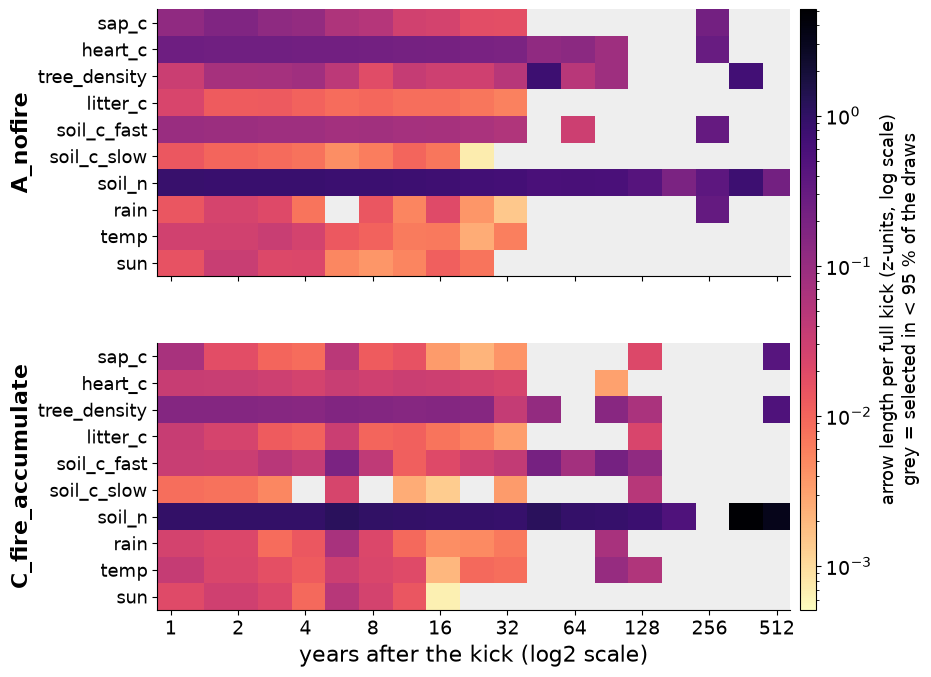

In [5]:
fig = pl.plot_heatmaps(results, HORIZONS, [k[2:] for k in kicks], MIN_SHARE)
fig.savefig(FIG + "state_heatmaps.png", dpi=130, bbox_inches="tight")

Why a heatmap: 10 kicks x 18 horizons x 2 modes are 360 numbers. A heatmap shows all of them at once, so patterns over time are visible. The colour scale is logarithmic because the arrow lengths span about four orders of magnitude, and sequential and perceptually uniform (`magma_r`, dark = strong), so it also works in greyscale. Both modes share one colour scale. Grey hides values that are not robust (selected in less than 95 % of the draws). The time axis is log2 because the horizons double.

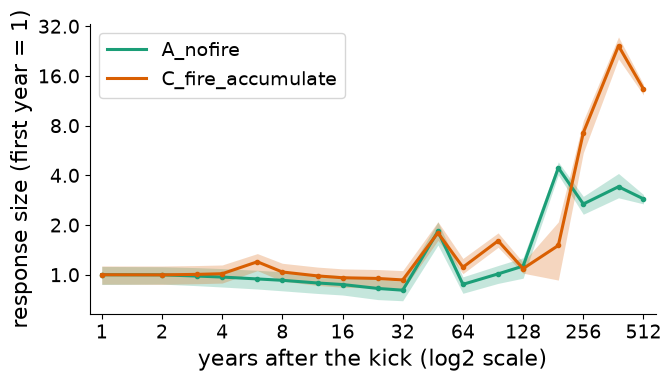

In [6]:
fig = pl.plot_modes(results, HORIZONS, "size", "response size (first year = 1)", relative=True, log=True)
fig.savefig(FIG + "state_size_modes.png", dpi=130)

Why this graph: a line per mode with its bootstrap range, both axes log2, because horizons double and growth or decay is multiplicative. Dividing by the first year lets the modes be compared despite different starting sizes. The two mode colours (Dark2 palette, colour-blind safe) are the same in every figure.

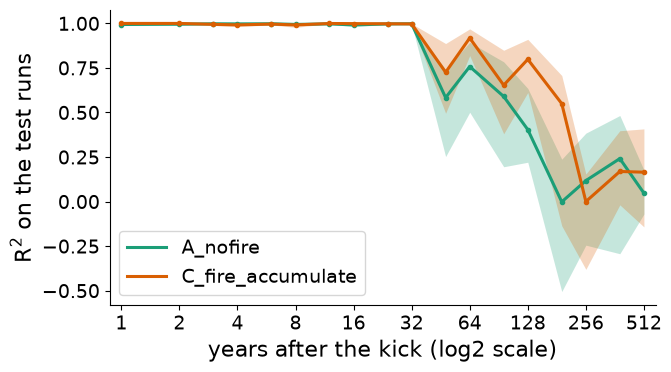

In [7]:
fig = pl.plot_modes(results, HORIZONS, "r2", "R$^2$ on the test runs")
fig.savefig(FIG + "state_r2_modes.png", dpi=130)

Why this graph: same layout as the response size, so the two can be read side by side. The y axis is linear because R2 is bounded and its reference values (1 = perfect, 0 = no better than the mean) matter more than ratios.

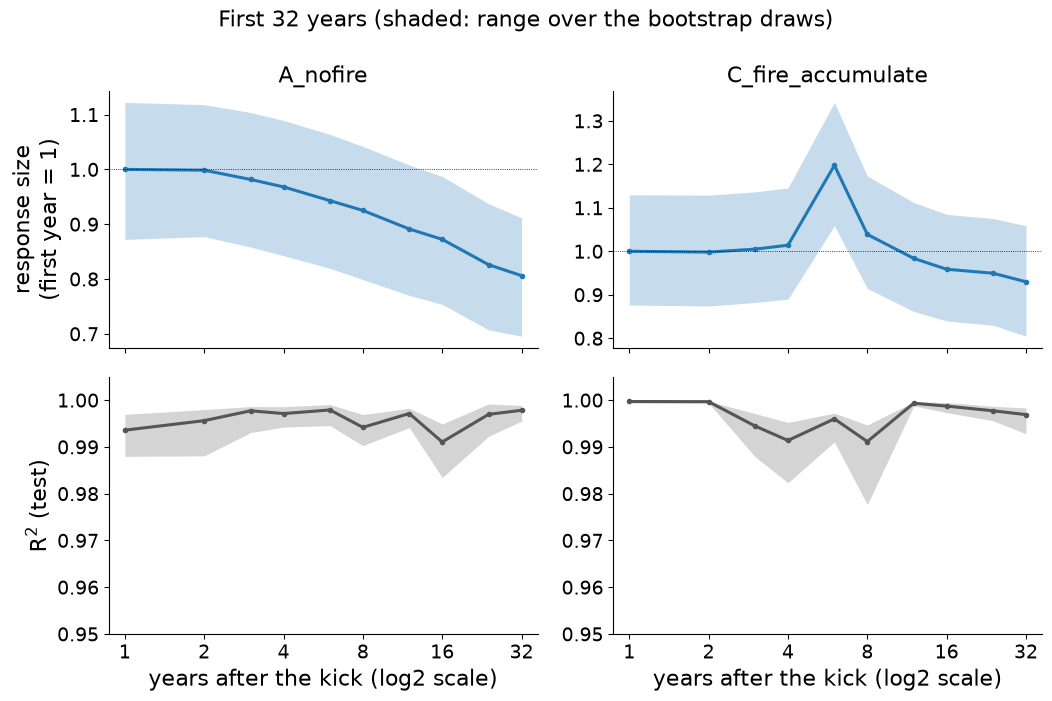

In [8]:
fig = pl.plot_first_years(results, HORIZONS, max_year=32)
fig.savefig(FIG + "state_response_first32.png", dpi=130)

Why this graph: a zoom into the first 32 years, one column per mode, with linear y axes because the changes are only a few per cent. R2 is grey so it is not mixed up with a mode colour.

## 4. Results in short

- For the first ~32 years the response is almost perfectly linear in the kicks (test R2 about 0.99 in both modes) and its size stays near the first-year value (slow decay without fire).
- Linear predictability (test R2 >= 0.5) lasts up to about 96 years without fire and up to about 192 years with fire. At 512 years R2 is close to 0 in both modes.
- After ~150 years the response grows (several-fold without fire, more than ten-fold with fire). The perturbation is not forgotten but amplified, and no longer linearly predictable.
- The soil-nitrogen kick dominates at every horizon. Most other kicks stop being robustly selected after 32-48 years (without fire, heartwood carbon and tree density last until about 100 years).

## Caveats of the experiment

- One grid cell, one control run, one restart state: the results describe this trajectory, not "the model".
- `soil_n` kicks only the nitrogen in soil organic matter, not mineral nitrogen.
- Single-year states at long horizons are noisy (period-2 oscillations, fire years).
- LASSO coefficients are shrunk towards zero, so arrow lengths are lower bounds.